**Author**: JW Debelius (justine.debelius@jhu.edu)<br>
**Project**: 017-Arg<br>
**Enviroment**: <br>
**Creation Date**: July 2021<br>
**Update Date**: November 2025

In [1]:
import itertools as it
import os
import re

import biom
from matplotlib import rcParams
import matplotlib.pyplot as plt
import matplotlib.colors as mpc
from matplotlib import ticker

import numpy as np
import pandas as pd
import scipy
import seaborn as sn
import skbio
import patsy
import statsmodels.formula.api as smf
import statsmodels.api as sms

from qiime2 import Artifact, Metadata, Visualization

import qiime2.plugins.taxa.actions as q2_taxa
import qiime2.plugins.feature_table.actions as q2_feature_table

import scripts.alpha_plots as ap


rcParams['font.sans-serif'] = ['Helvetica', 'Arial']
rcParams['pdf.fonttype'] = 42
np.set_printoptions(precision=5)

%matplotlib inline

/Users/jwd/miniconda3/envs/arg-amplicon-2025.7/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:11: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
abx_order = ['untreated', 'nitrofurantoin', 'pivmecillinam',
             'co-trimoxazole', 'ceftibuten', 'ciprofloxacin']
colors = ['#969696', '#009E73','#9D654C', 
          '#4E7705', '#098BD9',  '#CC79A7']
spectrum_order = ['untreated', 'narrow', 'broad']
alpha_metrics = ['observed_features', 'shannon', 'simpson']
abx_names = {str(i): abx for i, abx in enumerate(abx_order)}
abx_colors = {str(i): color for i, color in enumerate(colors)}
abx_colors2 = {i: color for i, color in enumerate(colors)}

# Data

## Metadata

In [3]:
meta_all = pd.read_csv('final-data/01.metadata/analysis_sample_meta.tsv',
                     sep='\t',
                     dtype=str)
meta_all.set_index('sample-id', inplace=True)
meta_all[['age', 'days_since_intervention', 'gtdb_depth']] = \
    meta_all[['age', 'days_since_intervention', 'gtdb_depth']].astype(float)

meta = meta_all[['host_subject_id', 'timepoint', 'days_since_intervention',
             'abx_code2', 'age', 'sex', 'vegetarian', 'extraction_no', 'after_travel_na_eu']].copy()
meta['period'] = (meta['timepoint'].astype(float) > 0) * 1 + \
    (meta['timepoint'].astype(float) > 3) * 1

## Tables

In [4]:
gene_table_q2 = Artifact.load('final-data/03.amr-tables/megares_table_q2.qza')
gene_label_q2 = Artifact.load('final-data/03.amr-tables/megares_taxa_q2.qza')

In [5]:
taxa_table_q2 = Artifact.load('final-data/02.tables/matched-species-gtdb.qza')

In [6]:
meta['ratio_amr_taxa'] = \
    gene_table_q2.view(pd.DataFrame).sum(axis=1) / \
    taxa_table_q2.view(pd.DataFrame).sum(axis=1)
meta['ratio_amr_taxa2'] = meta['ratio_amr_taxa'] * 1e3

# Depth fits

In [7]:
tp_depth_period_fit = smf.mixedlm(
    'ratio_amr_taxa2 ~ C(abx_code2)*C(period) + C(extraction_no) + C(after_travel_na_eu)',
    data=meta,
    groups=meta['host_subject_id']
).fit()

In [8]:
tp_depth_period_fit.summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                   Mixed Linear Model Regression Results
===========================================================================
Model:                  MixedLM     Dependent Variable:     ratio_amr_taxa2
No. Observations:       473         Method:                 REML           
No. Groups:             74          Scale:                  0.3972         
Min. group size:        4           Log-Likelihood:         -526.0879      
Max. group size:        7           Converged:              Yes            
Mean group size:        6.4                                                
---------------------------------------------------------------------------
                                 Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------------------
Intercept                         1.751    0.292  5.997 0.000  1.179  2.323
C(abx_code2)[T.1]                -0.106    0.343 -0.309 0.757 -0.779  0.566
C(abx_code2)[T.2]                -0.174    0.358 -0.486 0.627 -0.876  0.528
C(abx_code2)[T.3]                 0.218    0.331  0.658 0.510 -0.431  0.867
C(abx_code2)[T.4]                -0.089    0.346 -0.256 0.798 -0.767  0.589
C(abx_code2)[T.5]                -0.134    0.340 -0.395 0.693 -0.801  0.532
C(period)[T.1]                   -0.008    0.206 -0.037 0.971 -0.412  0.397
C(period)[T.2]                   -0.214    0.211 -1.015 0.310 -0.629  0.200
C(extraction_no)[T.Extraction 2]  0.021    0.237  0.090 0.928 -0.443  0.485
C(extraction_no)[T.Extraction 3] -0.157    0.251 -0.623 0.533 -0.649  0.336
C(extraction_no)[T.Extraction 4]  0.149    0.253  0.592 0.554 -0.346  0.644
C(extraction_no)[T.Extraction 5] -0.141    0.253 -0.556 0.578 -0.636  0.355
C(extraction_no)[T.Extraction 6]  0.121    0.247  0.489 0.624 -0.364  0.606
C(extraction_no)[T.Extraction 7] -0.389    0.317 -1.229 0.219 -1.010  0.231
C(after_travel_na_eu)[T.Yes]      0.097    0.125  0.776 0.438 -0.148  0.342
C(abx_code2)[T.1]:C(period)[T.1]  0.088    0.296  0.296 0.767 -0.492  0.667
C(abx_code2)[T.2]:C(period)[T.1]  0.159    0.311  0.511 0.610 -0.451  0.768
C(abx_code2)[T.3]:C(period)[T.1] -0.027    0.286 -0.096 0.924 -0.587  0.532
C(abx_code2)[T.4]:C(period)[T.1] -0.152    0.296 -0.514 0.607 -0.733  0.428
C(abx_code2)[T.5]:C(period)[T.1] -0.121    0.290 -0.418 0.676 -0.690  0.447
C(abx_code2)[T.1]:C(period)[T.2]  0.238    0.297  0.801 0.423 -0.344  0.820
C(abx_code2)[T.2]:C(period)[T.2]  0.482    0.321  1.504 0.132 -0.146  1.111
C(abx_code2)[T.3]:C(period)[T.2]  0.290    0.289  1.005 0.315 -0.276  0.856
C(abx_code2)[T.4]:C(period)[T.2]  0.215    0.300  0.717 0.473 -0.373  0.804
C(abx_code2)[T.5]:C(period)[T.2]  0.141    0.293  0.481 0.630 -0.433  0.715
Group Var                         0.314    0.116                           
===========================================================================

"""

In [9]:
tp_depth_period_fit.pvalues.loc[tp_depth_period_fit.pvalues < 0.05]

Intercept    2.012284e-09
Group Var    1.770948e-05
dtype: float64

In [10]:
depth_desc = meta.groupby(['abx_code2', 'timepoint'])['ratio_amr_taxa'].describe()
depth_desc['t'] = scipy.stats.t.ppf(0.975, depth_desc['count'] - 1)
depth_desc['ci'] = depth_desc['std'] / np.sqrt(depth_desc['count'] - 1) * depth_desc['t']
depth_desc.rename({str(i): i for i in np.arange(6)}, level='abx_code2', inplace=True)
depth_desc.rename({i: str(float(i)) for i in np.arange(7)}, 
                  level='timepoint', inplace=True)

In [11]:
depth_w = meta.copy()
depth_w['timepoint'] = depth_w['timepoint'].astype(float)
depth_w = depth_w.pivot(index=['abx_code2', 'host_subject_id'],
                        columns='timepoint',
                        values='ratio_amr_taxa')
depth_w

timepoint                       0.0       1.0       2.0       3.0       4.0  \
abx_code2 host_subject_id                                                     
0         1003             0.001522       NaN  0.001427  0.001320  0.001462   
          1007             0.001245       NaN  0.001631       NaN       NaN   
          1025             0.002114  0.001697  0.002076  0.001430  0.001501   
          1028             0.002400  0.001888  0.002192  0.002026  0.002801   
          1034             0.002156  0.002388       NaN  0.001976  0.000587   
...                             ...       ...       ...       ...       ...   
5         1056             0.002304  0.001735  0.002002  0.002178  0.001929   
          1065             0.002454  0.001932  0.002771  0.002097  0.002272   
          1094             0.000897  0.000390  0.000879  0.000651  0.000890   
          1095             0.001059       NaN  0.001229  0.000841  0.000920   
          1096             0.003039  0.001254  0.001385  0.001745  0.002037   

timepoint                       5.0       6.0  
abx_code2 host_subject_id                      
0         1003             0.001348  0.001186  
          1007             0.001032  0.001045  
          1025             0.001875  0.001290  
          1028             0.001854  0.002413  
          1034             0.001126  0.001190  
...                             ...       ...  
5         1056             0.001754  0.001627  
          1065             0.002952  0.002846  
          1094             0.001321  0.000426  
          1095                  NaN  0.000870  
          1096             0.002486  0.002585  

[74 rows x 7 columns]

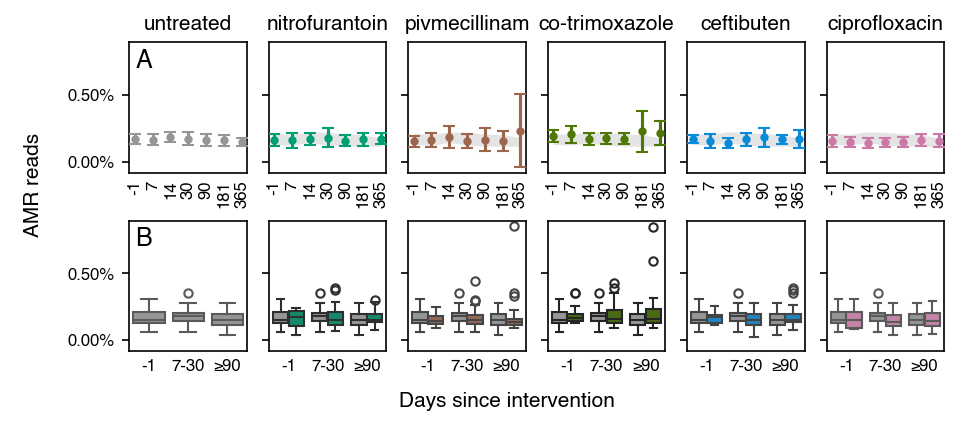

In [12]:
figa = plt.figure(dpi=150, constrained_layout=True, figsize=(6.25, 2.75))
[[figy, fig], [_, figx]] = figa.subfigures(2, 2, width_ratios=[0.25, 6], height_ratios=[2.5, 0.25])
gs = fig.add_gridspec(2, 6)
for i in np.arange(6):
    if i == 0:
        axa = fig.add_subplot(gs[0, i])
        # axb = fig.add_subplot(gs[1, i], sharex=axa, sharey=axa)
        axc = fig.add_subplot(gs[1, i], sharey=axa)
        sn.boxplot(ax=axc, x='period', y='ratio_amr_taxa',
                   data=meta.loc[meta['abx_code2'].isin(['0', 0])],
                   color=colors[0],
                   order=[0, 1, 2],
                   linewidth=1,
                   flierprops=dict(marker='o', markerfacecolor='None', markeredgewidth=1, markersize=4),
                   )
    else:
        axa = fig.add_subplot(gs[0, i], sharey=axa)
        # axb = fig.add_subplot(gs[1, i], sharey=axb, sharex=axa)
        axc = fig.add_subplot(gs[1, i], sharey=axc)
        sn.boxplot(ax=axc, x='period', y='ratio_amr_taxa', hue='abx_code2',
                   data=meta.loc[meta['abx_code2'].isin(['0', 0, i, str(i)])],
                   palette=abx_colors,
                   order=[0, 1, 2],
                   linewidth=1,
                   flierprops=dict(marker='o', markerfacecolor='None', markeredgewidth=1, markersize=4),
                   )
        axc.get_legend().set_visible(False)
    axa.set_title(abx_order[i], size=10)
    ap._plot_forest_square(ax=axa, abx=i, sum_df=depth_desc)

    
    for j, ax_ in enumerate([axa, axc]):
        ax_.yaxis.set_tick_params(left=True, right=False,
                                  labelleft=(i == 0), labelright=False, 
                                  labelsize=8)
        ax_.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:1.2%}'))
        ax_.yaxis.get_label().set_visible(False)
        ax_.xaxis.set_tick_params(bottom=False, top=False,
                                  labelbottom=True, labeltop=False, 
                                  labelsize=8, length=0)
        ax_.xaxis.get_label().set_visible(False)
        
    for j, ax_ in enumerate([axa]):
        ax_.set_xticks(np.arange(7))
        ax_.set_xticklabels(['-1', '7', '14', '30', '90', '181', '365'], 
                            rotation=90)
    axc.set_xticks([0, 1, 2])
    axc.set_xticklabels(['-1', '7-30', '≥90'])
    axc.xaxis.set_tick_params(labelbottom=True)

ap._add_labelfig(figy, 'AMR reads', rotation=90)
ap._add_labelfig(figx,  'Days since intervention', rotation=0)

for a, ax_ in zip(*('AB', fig.axes[0:2])):
    ax_.text(ax_.get_xlim()[0] + 0.05 * np.diff(ax_.get_xlim()),
             ax_.get_ylim()[1] - 0.05 * np.diff(ax_.get_ylim()),
             a,
             ha='left', va='top', size=12)

## AMR Poisson

We're going to transform the gene data into presence/absence

In [13]:
group_abund_q2, = q2_taxa.collapse(table=gene_table_q2,
                                   taxonomy=gene_label_q2,
                                   level=3)
group_pres_q2, = q2_feature_table.presence_absence(group_abund_q2)
# group_pres_rate = group_pres_q2.view(pd.DataFrame).mean(axis=0).to_frame()
# group_pres_rate.index.set_names('id', inplace=True)
# group_pres_rate.rename(columns={0: 'pres'}, inplace=True)
# group_pres_rate['subject_id'] = meta['host_subject_id']

In [14]:
group_pres = group_pres_q2.view(pd.DataFrame)
group_pres.index.set_names('sample-id', inplace=True)
group_pres.rename(columns={c: c.split(';')[-1] for c in group_pres.columns},
                   inplace=True)
group_pres.rename(columns={c: c.replace("-", '_') for c in group_pres.columns},
                   inplace=True)

group_pres['subject_id'] = meta['host_subject_id']
group_pres.set_index('subject_id', append=True, inplace=True)
subject_pres = group_pres.groupby('subject_id').max()
subject_pres = subject_pres.mean(axis=0)

keep_feat = subject_pres[(subject_pres >= 0.15) & 
                         (group_pres.mean(axis=0) > 0.1) & 
                         (group_pres.mean(axis=0) < 0.9)]

In [15]:
keep_feat2 = [i.split(';')[-1] for i in keep_feat.index]

In [16]:
pres_model = group_pres[keep_feat.index].copy()
pres_model.reset_index(level='subject_id', inplace=True, drop=True)
pres_model = pd.concat(
    axis=1, 
    objs=[meta, 
          pres_model.rename(columns={c: c.split(';')[-1] 
                                     for c in group_pres.columns})
         ]
)
pres_model['depth'] = np.log10(gene_table_q2.view(pd.DataFrame).sum(axis=1))
pres_model['timepoint'] = pres_model['timepoint'].astype(float)
fam = sms.families.Poisson()
ind = sms.cov_struct.Autoregressive()
gee_kwargs = dict(
    data=pres_model.reset_index(),
    groups='host_subject_id',
    time='timepoint',
    cov_struct=ind,
    family=fam,
)
# ref_eq = 'depth'
ref_eq = 'depth'
# ref_eq = 1

/Users/jwd/miniconda3/envs/arg-amplicon-2025.7/lib/python3.10/site-packages/statsmodels/genmod/cov_struct.py:796: FutureWarning: grid=True will become default in a future version
  warnings.warn(


In [17]:
%%capture
gee_fits = dict()
no_converge = []
fails = []

for col_ in keep_feat2:
    try:
        fit_ = smf.gee(f'{col_} ~ C(abx_code2)*C(period) + {ref_eq}', 
                       **gee_kwargs).fit()
        if fit_.converged:
            gee_fits[col_] = fit_
        if not fit_.converged:
            no_converge.append(col_)
    except:
        fails.append(col_)

In [18]:
len(fails)

7

In [19]:
group_pres[fails].mean()

Class_C_betalactamases                             0.150106
Tetracycline_resistance_MFS_efflux_pumps           0.156448
Mercury_resistance_protein                         0.103594
Sulfonamide_resistant_dihydropteroate_synthases    0.177590
Undecaprenyl_pyrophosphate_phosphatase             0.186047
Tetracycline_inactivation_enzymes                  0.463002
Iron_resistance_protein                            0.116279
dtype: float64

In [20]:
def _get_params(endog, fit_):
    """
    Extacts the params
    """
    params = pd.DataFrame.from_dict(
        orient='columns',
        data={'param': fit_.params,
              'bse': fit_.bse,
              't': fit_.tvalues,
              'p': fit_.pvalues,
              'ci_lo': fit_.conf_int()[0],
              'ci_hi': fit_.conf_int()[1],})
    params['endog'] = endog
    params.drop(index=['Intercept', 'depth'], inplace=True)

    return params
    

In [21]:
print(fails[0])
pres_model.groupby(['abx_code2', 'period'])[fails[0]].mean().unstack()


Class_C_betalactamases


period,0,1,2
abx_code2,,,
0,0.307692,0.114286,0.142857
1,0.250000,0.176471,0.151515
2,0.200000,0.250000,0.136364
3,0.142857,0.078947,0.200000
4,0.000000,0.117647,0.181818
5,0.076923,0.081081,0.171429


In [22]:
print(fails[1])
pres_model.groupby(['abx_code2', 'period'])[fails[0]].mean().unstack()


Tetracycline_resistance_MFS_efflux_pumps


period,0,1,2
abx_code2,,,
0,0.307692,0.114286,0.142857
1,0.250000,0.176471,0.151515
2,0.200000,0.250000,0.136364
3,0.142857,0.078947,0.200000
4,0.000000,0.117647,0.181818
5,0.076923,0.081081,0.171429


In [23]:
print(fails[2])
pres_model.groupby(['abx_code2', 'period'])[fails[0]].mean().unstack()


Mercury_resistance_protein


period,0,1,2
abx_code2,,,
0,0.307692,0.114286,0.142857
1,0.250000,0.176471,0.151515
2,0.200000,0.250000,0.136364
3,0.142857,0.078947,0.200000
4,0.000000,0.117647,0.181818
5,0.076923,0.081081,0.171429


In [24]:
def _get_params(endog, fit_):
    """
    Extacts the params
    """
    params = pd.DataFrame.from_dict(
        orient='columns',
        data={'param': fit_.params,
              'bse': fit_.bse,
              't': fit_.tvalues,
              'p': fit_.pvalues,
              'ci_lo': fit_.conf_int()[0],
              'ci_hi': fit_.conf_int()[1],})
    params['endog'] = endog
    params.drop(index=['Intercept', 'depth'], inplace=True)

    return params
    

In [25]:
def _find_abx(x):
    if 'abx_code' in x:
        span = re.search('abx_code2\)\[T.', x).span()[1]
        return x[span]
    else:
        return '0'
def _find_period(x):
    if 'period' in x:
        span = re.search('period\)\[T.', x).span()[1]
        return x[span]
    else:
        return '0'

In [26]:
gee_params = pd.concat(
    axis=0, 
    objs=[_get_params(endog, gee_fit) for endog, gee_fit in gee_fits.items()]
          )
gee_params['abx_code2'] = [_find_abx(i) for i in gee_params.index]
gee_params['period'] =  [_find_period(i) for i in gee_params.index]
gee_params.set_index(['endog', 'abx_code2', 'period'], inplace=True)

In [27]:
gee_params_p = gee_params['p'].unstack(0).T
gee_params_q = pd.DataFrame.from_dict(
    data={c: pd.Series(sms.stats.multipletests(v.dropna(), method='fdr_bh')[1], 
                       index=v.dropna().index)
          for c, v in gee_params_p.items()},
    orient='columns')
gee_params_q.columns.set_names(gee_params_p.columns.names, inplace=True)
gee_params['q'] = gee_params_q.unstack().reset_index().set_index(['endog', 'abx_code2', 'period'])[0]

In [28]:
colors2 = ['#B9B9B9', '#54BEA2', '#BE9888', '#8AA458', '#5BB1E5', '#DEA5C5']

/var/folders/kn/xj9fkj9d48b4n8kr507yzwl00000gn/T/ipykernel_10778/2341057277.py:47: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or axes decorations smaller.
  figa.savefig('output/figures/figures8_amrpath_gee.png', facecolor=None, dpi=300)
/var/folders/kn/xj9fkj9d48b4n8kr507yzwl00000gn/T/ipykernel_10778/2341057277.py:48: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or axes decorations smaller.
  figa.savefig('output/figures/figures8_amrpath_gee.pdf', facecolor=None, dpi=300)
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped
/Users/jwd/miniconda3/envs/arg-amplicon-2025.7/lib/python3.10/site-packages/IPython/core/events.py:82: UserWarning: constrained_layout not

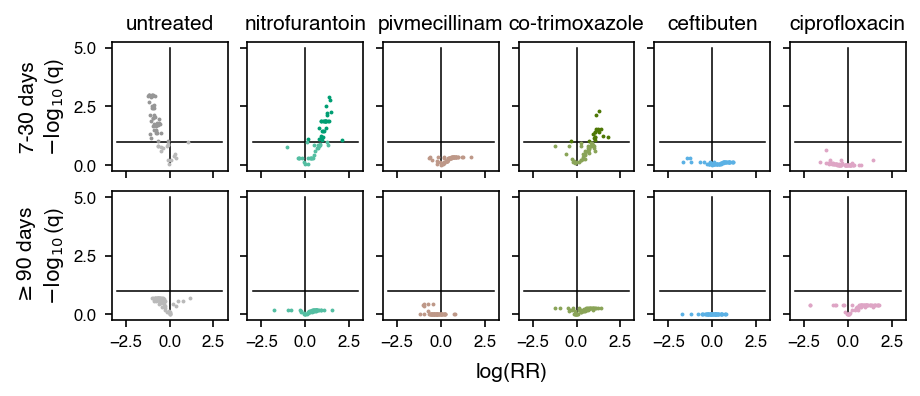

In [29]:
figa = plt.figure(dpi=150, constrained_layout=True, figsize=(6, 2.5))
fig, figl = figa.subfigures(2, 1, height_ratios=[2.35, 0.15])
gs = fig.add_gridspec(2, 6)
for abx in np.arange(6):
    for per in np.arange(2):
        if per == abx == 0:
            ax = fig.add_subplot(gs[per, abx])
        else:
            ax = fig.add_subplot(gs[per, abx], sharex=ax, sharey=ax)
        per = per + 1
        if abx == per == 0:
            ax.set_visible(False)
            continue
        df_ = gee_params.xs(str(abx), level='abx_code2')
        df_ = df_.xs(str(per), level='period')
        ax.scatter(x=df_.loc[df_['q'] < 0.1, 'param'],
                   y=-np.log10(df_.loc[df_['q'] < 0.1, 'q']),
                   marker='.',
                   c=colors[abx],
                   s=3,
                   zorder=2,
                   )
        ax.scatter(x=df_.loc[df_['q'] >= 0.1, 'param'],
                   y=-np.log10(df_.loc[df_['q'] >= 0.1, 'q']),
                   marker='.',
                   c=colors2[abx],
                   s=3,
                   zorder=2,
                   )
        ax.plot([0, 0], [0, 5], 'k-', linewidth=0.75, zorder=0)
        ax.plot([-3, 3], [1, 1], 'k-', linewidth=0.75, zorder=0)
        ax.set_yticks([0, 2.5, 5])
        ax.xaxis.set_tick_params(left=True, labelleft=(per == 2), labelsize=8)
        ax.yaxis.set_tick_params(left=True, labelleft=(abx == 0), labelsize=8)
        if per == 1:
            ax.set_title(abx_order[abx], size=10)
fig.axes[0].set_ylabel('7-30 days\n$-\\log_{10}$(q)', size=10)
fig.axes[1].set_ylabel('$\\geq$90 days\n$-\\log_{10}$(q)', size=10)
# axes[1][2].set_xlabel('log(RR)')
axl = figl.add_subplot(1,1,1, facecolor='None')
axl.text(0.5, 0.5, 'log(RR)', size=10, ha='center', va='center')
axl.set_xlim(-0.125, 1)
axl.yaxis.set_tick_params(left=False, right=False, labelleft=False, labelright=False, labelsize=0, length=0)
axl.xaxis.set_tick_params(left=False, right=False, labelleft=False, labelright=False, labelsize=0, length=0)
sn.despine(ax=axl, left=True, right=True, top=True, bottom=True)

figa.savefig('output/figures/figures8_amrpath_gee.png', facecolor=None, dpi=300)
figa.savefig('output/figures/figures8_amrpath_gee.pdf', facecolor=None, dpi=300)


In [30]:
gee_params2 = gee_params[['param', 'ci_lo', 'ci_hi', 'q']].copy()
gee_params2[['param', 'ci_lo', 'ci_hi']] = \
    gee_params2[['param', 'ci_lo', 'ci_hi']].round(2)
gee_params2.rename(columns={'param': 'beta'}, inplace=True)
gee_params2['beta'] = gee_params2['beta'].apply(lambda x: f'{x:1.2f}')
gee_params2['conf_int'] = \
    gee_params2.apply(lambda x: '({ci_lo:1.2f}, {ci_hi:1.2f})'.format(**x), axis=1)
gee_params2['q'] = gee_params2['q'].round(3).apply(lambda x: f'{x:1.2f}' if (x >= 0.01) else f'{x:1.3f}')
gee_params2.reset_index(inplace=True)
gee_params2 = \
    gee_params2.melt(id_vars=['endog', 'abx_code2', 'period'],
                     value_vars=['beta', 'conf_int', 'q'],
                     var_name='stat',
                     value_name='value')

gee_params2 = \
    gee_params2.pivot(index='endog', 
                      columns=['abx_code2', 'period', 'stat'],
                      values='value')

gee_params2.sort_index(axis='columns', ascending=True, inplace=True)
gee_params2.drop(columns=['0'], level='abx_code2', inplace=True)
gee_params2.rename(columns=abx_names, level='abx_code2', inplace=True)
gee_params2.rename(columns={'0': 'Baseline', '1': '7-30 days', '2': '≥90 days'},
                   inplace=True)
gee_params2.rename(columns={'beta': 'log(RR)', 'conf_int': '95% CI', 'q': 'FDR p-value'},
                   inplace=True,
                   level='stat')

In [31]:
with pd.ExcelWriter('output/tables/table_s4_amr_gee.xlsx') as f_:
    gee_params2.astype(str).to_excel(f_, sheet_name='gee')

In [32]:
gee_params2

abx_code2                                       nitrofurantoin                 \
period                                                Baseline                  
stat                                                   log(RR)         95% CI   
endog                                                                           
Acetate_resistance_protein                               -0.05  (-1.02, 0.93)   
Acid_resistance_protein                                  -0.51  (-1.36, 0.34)   
Acid_resistance_regulator                                -0.57  (-1.39, 0.24)   
Aminoglycoside_N_acetyltransferases                       0.55  (-0.56, 1.66)   
Aminoglycoside_O_phosphotransferases                     -0.20  (-0.75, 0.35)   
Aminoglycoside_efflux_pumps                              -0.33  (-1.47, 0.81)   
Arsenic_resistance_protein                               -0.59  (-1.43, 0.24)   
Arsenic_resistance_regulator                             -0.09  (-1.37, 1.20)   
Biocide_and_metal_ABC_efflux_pumps                       -0.38  (-1.28, 0.51)   
Biocide_and_metal_resistance_protein                     -0.71  (-1.50, 0.07)   
Chloramphenicol_acetyltransferases                        0.03  (-0.27, 0.33)   
Chromium_resistance_protein                              -0.28  (-1.14, 0.59)   
Copper_resistance_protein                                -0.71  (-1.49, 0.08)   
Copper_resistance_regulator                              -0.46  (-1.33, 0.41)   
Dihydrofolate_reductase                                  -0.13  (-0.40, 0.14)   
Drug_and_biocide_ABC_efflux_pumps                        -0.14  (-1.13, 0.85)   
Drug_and_biocide_MATE_efflux_pumps                       -0.10  (-0.28, 0.08)   
Drug_and_biocide_MFS_efflux_pumps                        -0.11  (-1.08, 0.87)   
Drug_and_biocide_MFS_efflux_regulator                    -0.30  (-1.14, 0.55)   
Drug_and_biocide_RND_efflux_pumps                        -0.58  (-1.38, 0.22)   
Drug_and_biocide_RND_efflux_regulator                    -0.58  (-1.36, 0.21)   
Drug_and_biocide_SMR_efflux_pumps                        -0.49  (-1.32, 0.34)   
Drug_and_biocide_and_metal_RND_efflux_pumps              -0.41  (-1.23, 0.41)   
Drug_and_biocide_and_metal_RND_efflux_regulator          -0.27  (-1.20, 0.66)   
Drug_and_biocide_and_metal_resistance_regulator          -0.46  (-1.35, 0.43)   
Lincosamide_nucleotidyltransferases                      -0.15  (-0.38, 0.09)   
Lipid_A_modification                                     -0.60  (-1.42, 0.23)   
MLS_resistance_ABC_efflux_pumps                           1.25  (-0.28, 2.77)   
MLS_resistance_MFS_efflux_pumps                           0.28  (-0.10, 0.66)   
Macrolide_phosphotransferases                            -0.62  (-2.29, 1.05)   
Multi_biocide_RND_efflux_pump                            -1.09  (-3.20, 1.01)   
Multi_biocide_SMR_efflux_pump                             0.29  (-0.78, 1.36)   
Multi_biocide_resistance_protein                         -0.28  (-1.15, 0.58)   
Multi_biocide_resistance_regulator                       -0.62  (-1.44, 0.20)   
Multi_drug_ABC_efflux_pumps                              -0.15  (-0.96, 0.65)   
Multi_drug_RND_efflux_pumps                              -1.07  (-2.41, 0.27)   
Multi_drug_RND_efflux_regulator                          -0.03  (-1.01, 0.95)   
Multi_metal_ABC_efflux_pumps                             -0.54  (-1.35, 0.26)   
Multi_metal_RND_efflux_pumps                             -0.38  (-1.27, 0.50)   
Multi_metal_RND_efflux_regulator                         -0.44  (-1.27, 0.39)   
Multi_metal_resistance_protein                           -0.73  (-1.53, 0.07)   
Multi_metal_resistance_regulator                         -0.12  (-0.81, 0.56)   
Mupirocin_resistant_isoleucyl_tRNA_synthetase             0.35  (-0.47, 1.16)   
Nickel_ABC_efflux_pumps                                  -0.28  (-1.15, 0.59)   
Nickel_ABC_efflux_regulator                              -0.22  (-0.92, 0.49)   
Penicillin_binding_protein     